In [1]:
import pandas as pd
import csv
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

def parse_protein_export(path, encoding="utf-8-sig"):
    rows, sample, analysis, protein, col = [], None, None, None, None
    to_int = lambda x: int(x) if x.isdigit() else None
    with open(path, newline="", encoding=encoding, errors="replace") as fh:
        for raw in csv.reader(fh, delimiter=";"):
            f = [c.strip() for c in raw]
            if not any(f):
                continue
            if f[0].startswith("Sample:"):
                sample = f[0].split(":", 1)[1].strip(); continue
            if any(c.startswith("Analysis:") for c in f):
                analysis = next(c for c in f if c.startswith("Analysis:")).split(":", 1)[1].strip(); continue
            if "Sequence" in f:                      # sub-header row -> column positions
                col = {name: i for i, name in enumerate(f) if name}
                col["pep#"] = col["Sequence"] - 1    # peptide '#' sits just before Sequence
                continue
            if col is None:                          # still in the top header block
                continue
            f += [""] * (len(col) + 10 - len(f))
            if f[0].isdigit():                       # new protein row
                protein = {
                    "protein": f[1],
                    "uniprot_id": f[2],
                    "protein_rank": int(f[0]),
                    **{f"protein_{k.lower().replace(' ', '_')}": to_int(f[col[k]])
                       for k in ("PSM", "All ions", "Distinct") if k in col},
                }
            seq = f[col["Sequence"]]
            if protein and seq:
                rows.append({"peptide": seq, **protein,
                             "peptide_index": to_int(f[col["pep#"]]),
                             "sample": sample, "analysis": analysis})
    return pd.DataFrame(rows)

In [3]:
metadata =  pd.read_csv("metadata.csv")
metadata

,sample,search_engine,fdr,path,DB,hla_alleles
0,1260,spectranaut,0.01,../data/Tumor_immunopeptidomics/1260.csv,uniprot_NT,HLA-A03:01|HLA-A33:01|HLA-B07:02|HLA-B14:02|HL...
1,1343,spectranaut,0.01,../data/Tumor_immunopeptidomics/1343.csv,uniprot_NT,HLA-A02:01|HLA-A01:01|HLA-B51:01|HLA-B37:01|HL...
2,1505,spectranaut,0.01,../data/Tumor_immunopeptidomics/1505.csv,uniprot_NT,HLA-A03:01|HLA-A03:01|HLA-B07:02|HLA-B38:01|HL...
3,1528,spectranaut,0.01,../data/Tumor_immunopeptidomics/1528.csv,uniprot_NT,HLA-A02:01|HLA-A24:02|HLA-B51:01|HLA-B38:01|HL...
4,1532,spectranaut,0.01,../data/Tumor_immunopeptidomics/1532.csv,uniprot_NT,HLA-A32:01|HLA-A11:01|HLA-B18:01|HLA-B52:01|HL...


In [4]:
rests = {}
for index, row in metadata.iterrows():
    sample = row['sample']
    df =  parse_protein_export(row['path'])
    rests[sample] = df

In [6]:
rests[1505]

,peptide,protein,uniprot_id,protein_rank,protein_psm,protein_all_ions,protein_distinct,peptide_index,sample,analysis
0,SRQFSSR,P04264,K2C1_HUMAN,1,239,261,239,1,VWF4758,VWF4758
1,SRQFSSRSG,P04264,K2C1_HUMAN,1,239,261,239,2,VWF4758,VWF4758
2,SRQFSSRSGY,P04264,K2C1_HUMAN,1,239,261,239,3,VWF4758,VWF4758
3,SRQFSSRSGYR,P04264,K2C1_HUMAN,1,239,261,239,4,VWF4758,VWF4758
4,SGYRSGGGF,P04264,K2C1_HUMAN,1,239,261,239,5,VWF4758,VWF4758
...,...,...,...,...,...,...,...,...,...,...
6831,AVQPPPALSR,TCONS_00390303_143_343,-,2973,6836,1,1,1,VWF4758,VWF4758
6832,IIFTPSLEK,TCONS_00524572_405_617,-,2974,6837,1,1,1,VWF4758,VWF4758
6833,SLLQPETPGLK,TCONS_00725445_104_187,-,2975,6838,1,1,1,VWF4758,VWF4758
6834,GPSGGRGAAL,TCONS_00819773_259_378,-,2976,6839,1,1,1,VWF4758,VWF4758


In [7]:
meta = pd.read_csv('../data/meta/20260219_EwS_ncORF_metadata_summary.tsv', sep='\t')
meta

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,NaN,NaN,NaN,0.0,False,not expressed,not expressed,upregulated,ns,ns
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,NaN,NaN,NaN,1.0,True,ns,ns,ns,ns,ns
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,NaN,NaN,NaN,0.0,False,not expressed,ns,upregulated,ns,ns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,NaN,NaN,NaN,0.0,False,ns,ns,ns,ns,ns
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,NaN,NaN,NaN,NaN,NaN,not expressed,ns,ns,ns,ns
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns


In [8]:
!mkdir -p HLA_binding
outDir = "HLA_binding"
os.chdir(outDir)

In [10]:
for sample in metadata['sample'].tolist():
    with open(f"{sample}.pep", 'w') as file:
        for pep in rests[sample]['peptide'].tolist():
            if 7<len(pep)<15:
                file.write(pep+'\n')

In [13]:
for sample in metadata['sample'].tolist():
    print("/home/mariia/Desktop/netMHCpan-4.1/netMHCpan", 
                    f"-a {(metadata.loc[metadata['sample'] == sample, 'hla_alleles'].values[0]).replace('|', ',')}",  # HLA alleles
                    f"-p {sample}.pep",            # peptide list
                    f"-xls -xlsfile {sample}_NetMHCpan_out.xls")

/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A03:01,HLA-A33:01,HLA-B07:02,HLA-B14:02,HLA-C07:02,HLA-C08:02 -p 1260.pep -xls -xlsfile 1260_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A01:01,HLA-B51:01,HLA-B37:01,HLA-C14:02,HLA-C06:02 -p 1343.pep -xls -xlsfile 1343_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A03:01,HLA-A03:01,HLA-B07:02,HLA-B38:01,HLA-C07:02,HLA-C12:03 -p 1505.pep -xls -xlsfile 1505_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A02:01,HLA-A24:02,HLA-B51:01,HLA-B38:01,HLA-C16:02,HLA-C12:03 -p 1528.pep -xls -xlsfile 1528_NetMHCpan_out.xls
/home/mariia/Desktop/netMHCpan-4.1/netMHCpan -a HLA-A32:01,HLA-A11:01,HLA-B18:01,HLA-B52:01,HLA-C12:03,HLA-C12:02 -p 1532.pep -xls -xlsfile 1532_NetMHCpan_out.xls


In [11]:
def plot_NetMHCpan_binding_results(sample):
    df = pd.read_csv(f'{sample}_NetMHCpan_out.xls', index_col=1, sep="\t", header=1) 
    with open(f'{sample}_NetMHCpan_out.xls') as my_file:
        hlas = my_file.readline().rstrip('\n').strip('\t').split('\t\t\t\t')
    df = df.rename(columns={'EL_Rank': 'EL_Rank.0'})
    df =df.reset_index()

    #plot all per allele
    counts_strong = []
    counts_weak = []
    for i, hla in enumerate(hlas):
        df[f'Strong_binder_{hla}'] = df[f'EL_Rank.{i}']<0.5
        df[f'Weak_binder_{hla}'] = (df[f'EL_Rank.{i}']<2)&(df[f'EL_Rank.{i}']>=0.5)
        counts_strong.append(df[f'Strong_binder_{hla}'].sum())
        counts_weak.append(df[f'Weak_binder_{hla}'].sum())
    allele_binder_counts = pd.DataFrame.from_dict({'Allele': hlas, 'Count_strong': counts_strong, 'Count_weak': counts_weak})
    #print(allele_binder_counts)
    bar = allele_binder_counts.plot(kind = 'bar',x='Allele', stacked = True, color = ["#00008b", "#4169e1"], zorder=2)
    bar.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray', zorder=0)
    for i, row in allele_binder_counts.iterrows():
        plt.text(i, row['Count_strong'], str(row['Count_strong']), ha="center", va="bottom", zorder=3)
        plt.text(i, row['Count_strong']+row['Count_weak'], str(row['Count_weak']), ha="center", va="bottom", zorder=3)
    bar.set_ylabel("Count of binders per allele")
    bar.set_title(f"All {sample} \n NetMHCpan", fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine()
    plt.tight_layout()
    #plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_all_perall.png", dpi=600, bbox_inches='tight')
    plt.show()

    #plot all total
    df['Binder'] = df['NB'] != 0
    plt.figure(figsize=(2, 3))
    bar_plot = sns.barplot(df, y='Binder', errorbar=None, color="#00008b", zorder=3)
    bar_plot.text(0,  df['Binder'].mean(), df['Binder'].sum(), ha="center", va="bottom", zorder=2)
    bar_plot.yaxis.grid(True, linestyle='--', linewidth=0.5, color='lightgray')
    bar_plot.set(ylim=(None, 1.0))
    bar_plot.set_ylabel("Fraction of binders")
    bar_plot.set_title(f"All {sample} \n NetMHCpan", fontsize=16, weight='bold')
    sns.despine()
    plt.tight_layout()
    #plt.savefig(f"{run_.sample}_{run_.search_engine}_{run_.fdr}_NetMHCpan_binding_all.png", dpi=600, bbox_inches='tight')
    plt.show()

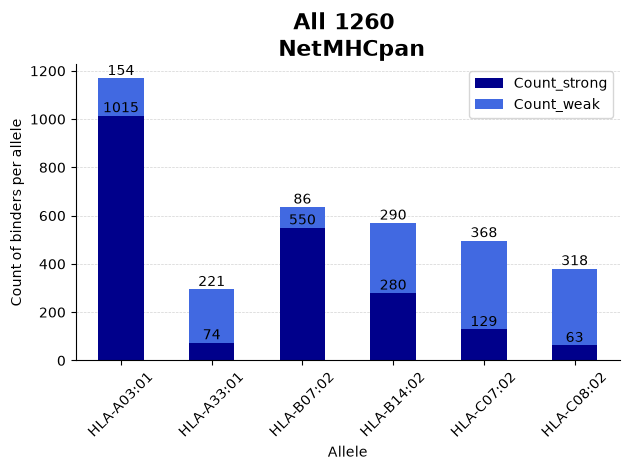

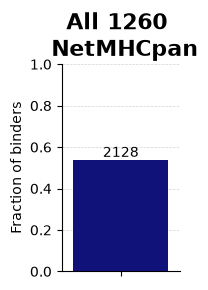

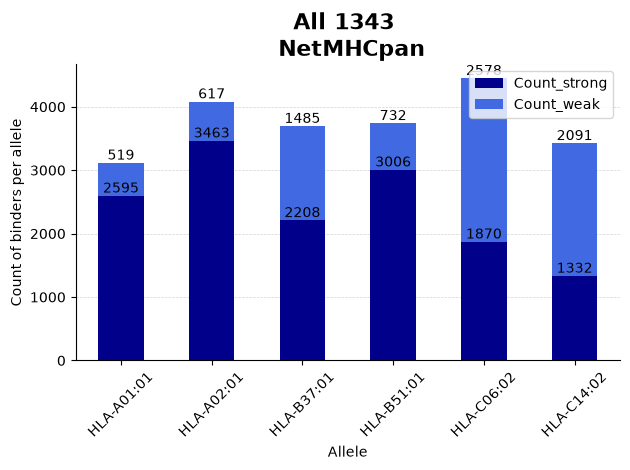

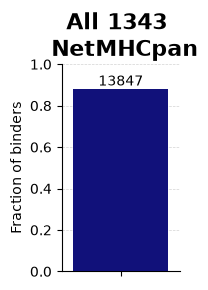

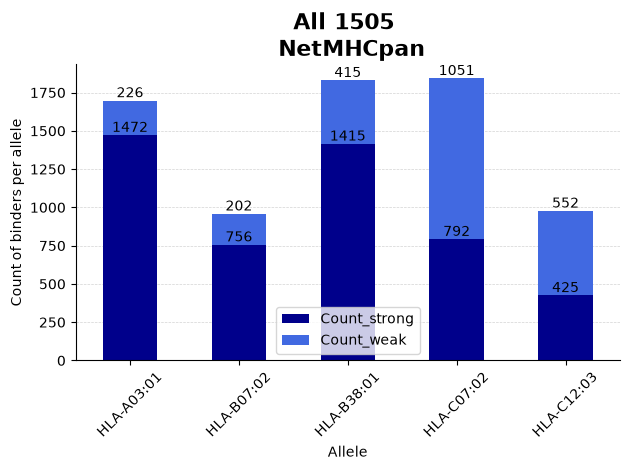

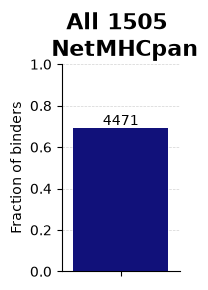

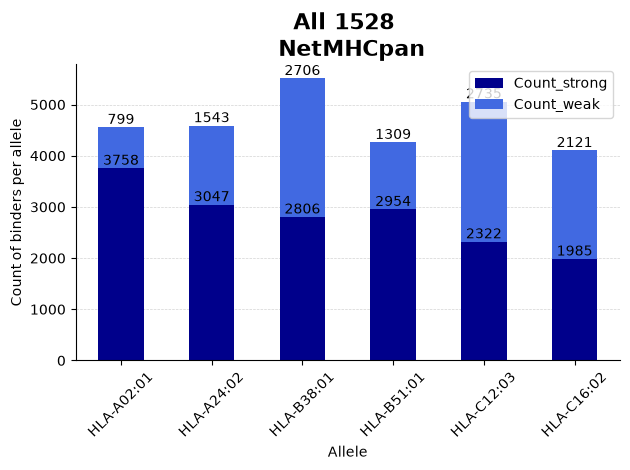

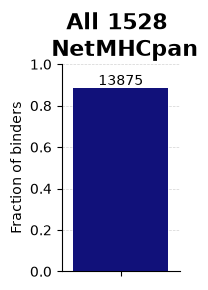

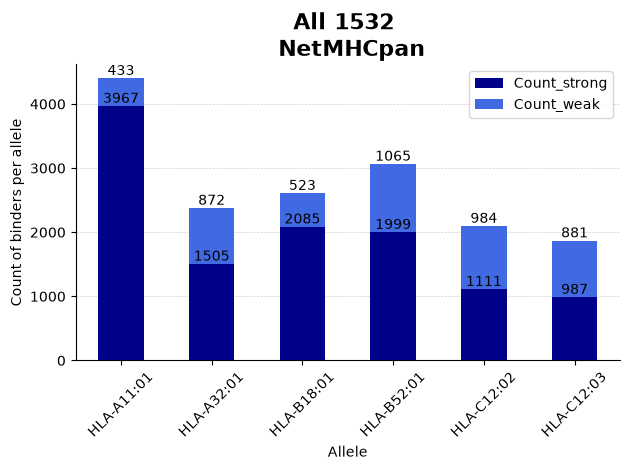

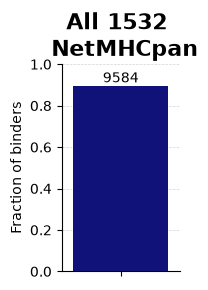

In [12]:
for sample in metadata['sample'].tolist():
    plot_NetMHCpan_binding_results(sample)

In [16]:
os.chdir("..")

In [17]:
h = []
for sample in metadata['sample'].tolist():
    df = pd.read_csv(f'HLA_binding/{sample}_NetMHCpan_out.xls', sep="\t", header=1) 
    with open(f'HLA_binding/{sample}_NetMHCpan_out.xls') as my_file:
        hlas = my_file.readline().rstrip('\n').strip('\t').split('\t\t\t\t')
    ranks = [column for column in df.columns if column.startswith('EL_Rank')]
    new_cols = ['Peptide', 'NB']
    new_cols.extend(ranks)
    df = df[new_cols].rename(columns=dict(zip(ranks,list(map(lambda x: x+'_rank_NetMHCpan', hlas)))))
    df['SB'] = [[] for _ in range(len(df))]
    df['WB'] = [[] for _ in range(len(df))]
    for hla in hlas:
        df['SB'] = df.apply(
									lambda x: x['SB'] + [hla] if x[f'{hla}_rank_NetMHCpan'] < 0.5 else x['SB'],
									axis=1
							)
        df['WB'] = df.apply(
									lambda x: x['WB'] + [hla] if 0.5 <= x[f'{hla}_rank_NetMHCpan'] < 2 else x['WB'],
									axis=1
							)
    df['Binder'] = df['NB'] != 0
    columns_to_keep_df = ['Peptide', 'Binder', 'SB', 'WB']
    df = df[columns_to_keep_df]
    df = df.rename(columns={'Peptide': 'seq_clear'})
    res = rests[sample][rests[sample]['uniprot_id']=='-']
    res = res.merge(df, left_on='peptide', right_on='seq_clear', how='left')
    res['Binder'] = res['Binder'].fillna(value=False)
    res['sample'] = sample
    h.append(res[res['Binder']])
total_noncanonical_binder_peptides_fp = pd.concat(h, ignore_index=True)
total_noncanonical_binder_peptides_fp

/tmp/ipykernel_706933/1024467727.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  res['Binder'] = res['Binder'].fillna(value=False)
/tmp/ipykernel_706933/1024467727.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  res['Binder'] = res['Binder'].fillna(value=False)
/tmp/ipykernel_706933/1024467727.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downc

,peptide,protein,uniprot_id,protein_rank,protein_psm,protein_all_ions,peptide_index,sample,analysis,seq_clear,Binder,SB,WB,protein_distinct
0,MTMSTILSK,ENST00000664641_241_333,-,171,3,3,1,1260,VWF4759,MTMSTILSK,True,[HLA-A03:01],[HLA-A33:01],NaN
1,MTMSTILSKK,ENST00000664641_241_333,-,171,3,3,2,1260,VWF4759,MTMSTILSKK,True,[HLA-A03:01],[],NaN
2,MTMSTILSKK,ENST00000664641_241_333,-,171,3,3,2,1260,VWF4759,MTMSTILSKK,True,[HLA-A03:01],[],NaN
3,MTMSTILSKK,ENST00000664641_241_333,-,171,3,3,3,1260,VWF4759,MTMSTILSKK,True,[HLA-A03:01],[],NaN
4,MTMSTILSKK,ENST00000664641_241_333,-,171,3,3,3,1260,VWF4759,MTMSTILSKK,True,[HLA-A03:01],[],NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741,SLLQPETPGLK,TCONS_00725445_104_187,-,5018,11010,1,1,1532,VWF4756,SLLQPETPGLK,True,[],[HLA-A11:01],NaN
742,VMAGTRIVW,TCONS_00766535_284_430,-,5019,11011,1,1,1532,VWF4756,VMAGTRIVW,True,[HLA-A32:01],"[HLA-C12:02, HLA-C12:03]",NaN
743,TVFGNSAFLKK,XLOC_013861__TCONS_00105559__ncRNA__28__AGG,-,5020,11012,1,1,1532,VWF4756,TVFGNSAFLKK,True,[HLA-A11:01],[],NaN
744,MILLPQPPK,XLOC_023655__TCONS_00179145__ncRNA__0__CTG,-,5021,11013,1,1,1532,VWF4756,MILLPQPPK,True,[HLA-A11:01],[],NaN


In [18]:
meta['orf_cathegoty_toplot'] = meta['neotranscript_orf_type'].where(meta['neotranscript_orf_type'] != 'Non-canonical ORF general', meta['orf_category_new'])

In [28]:
meta['orf_id_cropped'] = meta['orf_id'].str[:50]

In [29]:
merge = total_noncanonical_binder_peptides_fp.merge(meta, right_on='orf_id_cropped', left_on='protein', how='left')

In [30]:
merge['orf_cathegoty_toplot'].unique()

array(['lncRNA ORF', 'uORF', 'intORF', 'pseudogene ORF', 'uoORF',
       'ORF_variant', 'dORF', nan, 'doORF', 'unannotated gene ORF',
       'Neogene ORF', 'ORF_annotated'], dtype=object)

In [31]:
merge['orf_cathegoty_toplot'].fillna('Neogene ORF', inplace=True)

/tmp/ipykernel_706933/571881577.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merge['orf_cathegoty_toplot'].fillna('Neogene ORF', inplace=True)


In [32]:
merge.drop_duplicates(subset='peptide')['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
uORF                    172
intORF                   76
lncRNA ORF               68
uoORF                    59
Neogene ORF              22
pseudogene ORF           13
ORF_variant               5
doORF                     5
dORF                      4
unannotated gene ORF      2
ORF_annotated             1
Name: count, dtype: int64

In [36]:
x = merge.drop_duplicates(subset='peptide')
x[x['orf_cathegoty_toplot'] == 'Neogene ORF']

,peptide,protein,uniprot_id,protein_rank,protein_psm,protein_all_ions,peptide_index,sample,analysis,seq_clear,...,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES,orf_cathegoty_toplot,orf_id_cropped
102,AAMNILVYV,ORF47_Ew_NG8_5_788_1009,-,2371,2,2,1,1343,ZVW9360,AAMNILVYV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
103,KILDYMENL,ORF47_Ew_NG8_5_788_1009,-,2371,2,2,2,1343,ZVW9360,KILDYMENL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
209,ALWDSVFRA,ORF21_Ew_NG11_1_4635_5297,-,4058,13704,1,1,1343,ZVW9360,ALWDSVFRA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
210,AFQLSKEY,ORF52_Ew_NG8_4_11982_12092,-,4060,13706,1,1,1343,ZVW9360,AFQLSKEY,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
211,SFSDCSMLVY,ORF59_Ew_NG17_7_4096_4185,-,4061,13707,1,1,1343,ZVW9360,SFSDCSMLVY,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
212,MLIPWAIKL,ORF5_Ew_NG13_1_807_1061,-,4062,13708,1,1,1343,ZVW9360,MLIPWAIKL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
213,MKFLGIITL,ORF73_Ew_NG11_1_7519_7650,-,4063,13709,1,1,1343,ZVW9360,MKFLGIITL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
214,LVDFGSRSLY,ORF85_Ew_NG8_4_2482_2589,-,4065,13711,1,1,1343,ZVW9360,LVDFGSRSLY,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN
393,MAIPHLKIM,ENSG00000236894_ENSG00000279212__Ew_NG11.4__nc...,-,2166,2,2,1,1528,VWF4757,MAIPHLKIM,...,17.0,0.0,False,not expressed,not expressed,ns,ns,ns,Neogene ORF,ENSG00000236894_ENSG00000279212__Ew_NG11.4__nc...
512,RLYDQSVFL,ORF25_Ew_NG4_PACBIO_695_922,-,4002,13852,1,1,1528,VWF4757,RLYDQSVFL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Neogene ORF,NaN


In [35]:
for peptide in x[x['orf_cathegoty_toplot'] == 'Neogene ORF']['peptide'].tolist():
    print(f'grep "{peptide}" 20260219_EwS_ncORF_metadata_summary.tsv')

grep "AAMNILVYV" 20260219_EwS_ncORF_metadata_summary.tsv
grep "KILDYMENL" 20260219_EwS_ncORF_metadata_summary.tsv
grep "ALWDSVFRA" 20260219_EwS_ncORF_metadata_summary.tsv
grep "AFQLSKEY" 20260219_EwS_ncORF_metadata_summary.tsv
grep "SFSDCSMLVY" 20260219_EwS_ncORF_metadata_summary.tsv
grep "MLIPWAIKL" 20260219_EwS_ncORF_metadata_summary.tsv
grep "MKFLGIITL" 20260219_EwS_ncORF_metadata_summary.tsv
grep "LVDFGSRSLY" 20260219_EwS_ncORF_metadata_summary.tsv
grep "MAIPHLKIM" 20260219_EwS_ncORF_metadata_summary.tsv
grep "RLYDQSVFL" 20260219_EwS_ncORF_metadata_summary.tsv
grep "NELLTEQF" 20260219_EwS_ncORF_metadata_summary.tsv
grep "RTSTATLLF" 20260219_EwS_ncORF_metadata_summary.tsv
grep "RVNSQTLTF" 20260219_EwS_ncORF_metadata_summary.tsv
grep "RVAELLVSW" 20260219_EwS_ncORF_metadata_summary.tsv
grep "AILLPQLPK" 20260219_EwS_ncORF_metadata_summary.tsv
grep "AILLPQPPK" 20260219_EwS_ncORF_metadata_summary.tsv
grep "VILLPQPPK" 20260219_EwS_ncORF_metadata_summary.tsv
grep "VVFSLPVSK" 20260219_EwS_n

In [38]:
x[x['orf_cathegoty_toplot'] == 'Neogene ORF']['protein'].tolist()

['ORF47_Ew_NG8_5_788_1009',
 'ORF47_Ew_NG8_5_788_1009',
 'ORF21_Ew_NG11_1_4635_5297',
 'ORF52_Ew_NG8_4_11982_12092',
 'ORF59_Ew_NG17_7_4096_4185',
 'ORF5_Ew_NG13_1_807_1061',
 'ORF73_Ew_NG11_1_7519_7650',
 'ORF85_Ew_NG8_4_2482_2589',
 'ENSG00000236894_ENSG00000279212__Ew_NG11.4__ncRNA_',
 'ORF25_Ew_NG4_PACBIO_695_922',
 'ENSG00000226435_ENSG00000212297__ENST00000455355__',
 'ENSG00000226435_ENSG00000212297__ENST00000455355__',
 'ENSG00000251460_XLOC_075126__TCONS_00632959__ncRNA',
 'ENSG00000251460_XLOC_075126__TCONS_00632959__ncRNA',
 'ENST00000559870_381_524',
 'ORF104_Ew_NG8_4_7042_7152',
 'ORF12_Ew_NG9_1_2292_2378',
 'ORF25_Ew_NG8_2_1339_1422',
 'ORF3_Ew_NG15_1_303_398',
 'ORF3_Ew_NG6_3_282_422',
 'ORF84_Ew_NG8_4_2296_2457',
 'XLOC_013861__TCONS_00105559__ncRNA__28__AGG']

In [ ]:
rename_d ={'ORF47_Ew_NG8_5_788_1009':'TCONS_00808337_14985_15092',
 'ORF47_Ew_NG8_5_788_1009',
 'ORF21_Ew_NG11_1_4635_5297',
 'ORF52_Ew_NG8_4_11982_12092',
 'ORF59_Ew_NG17_7_4096_4185',
 'ORF5_Ew_NG13_1_807_1061',
 'ORF73_Ew_NG11_1_7519_7650',
 'ORF85_Ew_NG8_4_2482_2589',
 'ORF25_Ew_NG4_PACBIO_695_922',
 'ORF104_Ew_NG8_4_7042_7152',
 'ORF12_Ew_NG9_1_2292_2378',
 'ORF25_Ew_NG8_2_1339_1422',
 'ORF3_Ew_NG15_1_303_398',
 'ORF3_Ew_NG6_3_282_422',
 'ORF84_Ew_NG8_4_2296_2457'   
}